# Day 5: Regularization, Multi-class Classification and Wrap-up (Notebook 3 continued)

**Part A:** Breast Cancer model par dropout, weight decay aur early stopping lagana, aur before/after curves compare karna.
**Part B:** Iris par multi-class classifier (3 outputs, `CrossEntropyLoss`, softmax) aur confusion matrix.

In [1]:
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.datasets import load_breast_cancer, load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report)

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
import os
IMG_DIR = "../images" if os.path.basename(os.getcwd()) == "notebooks" else "images"
os.makedirs(IMG_DIR, exist_ok=True)

## Theory recap

- **Overfitting:** train loss girta rehta hai, validation loss upar jane lagta hai, aur dono ke beech gap badhta hai.
- **Underfitting:** train aur validation, dono loss high rehte hain.
- **Dropout:** training me har step par kuch neurons randomly band. `model.eval()` par dropout off ho jata hai.
- **Weight decay (L2):** bade weights ko penalize karta hai. `torch.optim.Adam(..., weight_decay=...)`.
- **Early stopping:** validation loss improve na ho to `patience` epochs ke baad ruk jao aur best weights wapas load karo.

## Part A: Regularization (Breast Cancer)

Day 4 jaisa hi split (70/15/15, stratified, random_state=42) aur scaling (sirf train par fit).

In [2]:
data = load_breast_cancer()
X, y = data.data, data.target

X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.15 / 0.85, stratify=y_temp, random_state=SEED)

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_val_s   = scaler.transform(X_val)
X_test_s  = scaler.transform(X_test)

print("train:", X_train_s.shape, " val:", X_val_s.shape, " test:", X_test_s.shape)

train: (397, 30)  val: (86, 30)  test: (86, 30)


In [3]:
def to_tensors(X, y):
    return (torch.tensor(X, dtype=torch.float32),
            torch.tensor(y, dtype=torch.float32).reshape(-1, 1))

X_train_t, y_train_t = to_tensors(X_train_s, y_train)
X_val_t,   y_val_t   = to_tensors(X_val_s,   y_val)
X_test_t,  y_test_t  = to_tensors(X_test_s,  y_test)

train_ds = TensorDataset(X_train_t, y_train_t)

### Model (dropout optional)

Hidden layers Day 4 se thori badi (64, 32) rakhi hain taake overfitting dikhne ka mauka mile.

In [4]:
class MLP(nn.Module):
    def __init__(self, n_in, hidden=(64, 32), n_out=1, dropout=0.0):
        super().__init__()
        layers, prev = [], n_in
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU()]
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, n_out))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

print(MLP(30, (64, 32), 1, dropout=0.3))

MLP(
  (net): Sequential(
    (0): Linear(in_features=30, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [5]:
def evaluate_binary(model, X, y, criterion):
    model.eval()                      # dropout off
    with torch.no_grad():
        logits = model(X)
        loss = criterion(logits, y).item()
        acc = ((torch.sigmoid(logits) > 0.5).float() == y).float().mean().item()
    return loss, acc

def train_binary(hidden=(64, 32), dropout=0.0, weight_decay=0.0, epochs=200,
                 lr=1e-3, patience=None, seed=SEED, batch_size=32):
    torch.manual_seed(seed)
    model = MLP(30, hidden, 1, dropout)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)

    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val, best_state, wait = float("inf"), None, 0

    for epoch in range(epochs):
        model.train()                 # dropout on
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()

        tl, ta = evaluate_binary(model, X_train_t, y_train_t, criterion)
        vl, va = evaluate_binary(model, X_val_t,   y_val_t,   criterion)
        hist["train_loss"].append(tl); hist["train_acc"].append(ta)
        hist["val_loss"].append(vl);   hist["val_acc"].append(va)

        if patience is not None:      # early stopping on validation loss
            if vl < best_val - 1e-4:
                best_val, best_state, wait = vl, copy.deepcopy(model.state_dict()), 0
            else:
                wait += 1
                if wait >= patience:
                    break

    if best_state is not None:        # best epoch ke weights wapas
        model.load_state_dict(best_state)
    return model, hist

### Chaar setups compare karo

1. Baseline (koi regularization nahi)
2. + Dropout
3. + Weight decay
4. Dropout + weight decay + early stopping

Selection (early stopping) validation loss par hoti hai. Test accuracy sirf report ke liye hai.

In [6]:
setups = {
    "Baseline":                         dict(),
    "+ Dropout (0.3)":                  dict(dropout=0.3),
    "+ Weight decay (1e-3)":            dict(weight_decay=1e-3),
    "Dropout + WD + Early stopping":    dict(dropout=0.3, weight_decay=1e-3, patience=20),
}

criterion = nn.BCEWithLogitsLoss()
histories, rows = {}, []

for name, kwargs in setups.items():
    model, hist = train_binary(**kwargs)
    histories[name] = hist
    _, test_acc = evaluate_binary(model, X_test_t, y_test_t, criterion)
    rows.append({
        "Setup": name,
        "Epochs trained": len(hist["val_loss"]),
        "Best val loss": min(hist["val_loss"]),
        "Final train loss": hist["train_loss"][-1],
        "Final val loss": hist["val_loss"][-1],
        "Gap (val - train)": hist["val_loss"][-1] - hist["train_loss"][-1],
        "Test acc": test_acc,
    })

results = pd.DataFrame(rows).set_index("Setup").round(4)
results

,Epochs trained,Best val loss,Final train loss,Final val loss,Gap (val - train),Test acc
Setup,,,,,,
Baseline,200,0.0019,0.0001,0.0021,0.0020,0.9419
+ Dropout (0.3),200,0.0002,0.0004,0.0006,0.0002,0.9419
+ Weight decay (1e-3),200,0.0073,0.0028,0.0098,0.0070,0.9419
Dropout + WD + Early stopping,112,0.0043,0.0058,0.0128,0.0071,0.9535


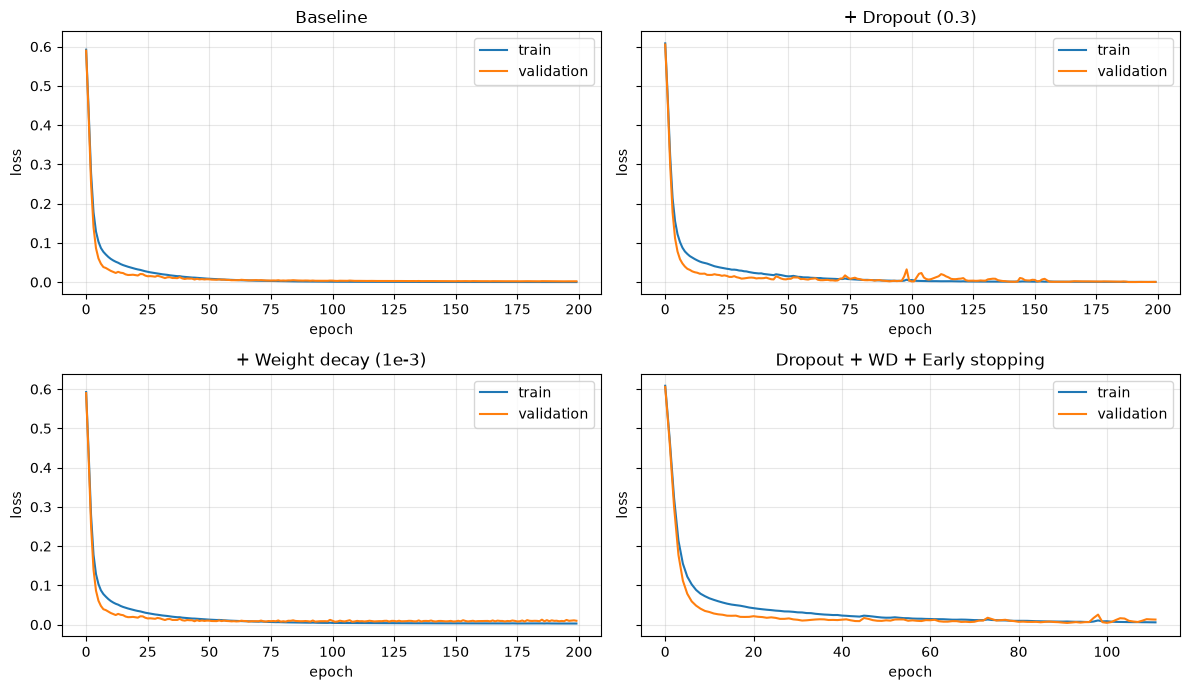

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharey=True)
for ax, (name, hist) in zip(axes.ravel(), histories.items()):
    ax.plot(hist["train_loss"], label="train")
    ax.plot(hist["val_loss"], label="validation")
    ax.set_title(name)
    ax.set_xlabel("epoch"); ax.set_ylabel("loss")
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/regularization_curves.png", dpi=150, bbox_inches="tight")
plt.show()

**Dhyan se dekho:**
- Baseline me val loss upar jata hai ya train se gap badhta hai? Wahi overfitting hai.
- Regularization ke baad gap kam hua? Early stopping kis epoch par ruki?
- Breast Cancer chhota aur aasan dataset hai, isliye overfitting halki ho sakti hai. Jo curves dikhen wahi honestly README me likho, forcefully improvement mat dikhao.
- Test set chhota hai (86 samples), isliye 1% ka farq noise ho sakta hai.

## Part B: Multi-class classifier (Iris)

- 3 classes, to output layer me 3 units.
- `CrossEntropyLoss` **raw logits** aur integer labels (0, 1, 2) leta hai. Isme softmax andar hota hai, isliye model ke end par softmax **nahi** lagate.
- Probabilities chahiye ho to sirf display ke liye `softmax` lagao.

In [8]:
iris = load_iris()
Xi, yi = iris.data, iris.target
print("shape:", Xi.shape, " classes:", {str(n): int(c) for n, c in zip(iris.target_names, np.bincount(yi))})

Xi_temp, Xi_test, yi_temp, yi_test = train_test_split(
    Xi, yi, test_size=0.15, stratify=yi, random_state=SEED)
Xi_train, Xi_val, yi_train, yi_val = train_test_split(
    Xi_temp, yi_temp, test_size=0.15 / 0.85, stratify=yi_temp, random_state=SEED)

iris_scaler = StandardScaler().fit(Xi_train)
def prep(X, y):
    return (torch.tensor(iris_scaler.transform(X), dtype=torch.float32),
            torch.tensor(y, dtype=torch.long))      # CrossEntropyLoss: long labels, shape (N,)

Xi_train_t, yi_train_t = prep(Xi_train, yi_train)
Xi_val_t,   yi_val_t   = prep(Xi_val,   yi_val)
Xi_test_t,  yi_test_t  = prep(Xi_test,  yi_test)
print("train:", len(yi_train), " val:", len(yi_val), " test:", len(yi_test))

shape: (150, 4)  classes: {'setosa': 50, 'versicolor': 50, 'virginica': 50}
train: 104  val: 23  test: 23


final train acc 1.000 | val acc 1.000


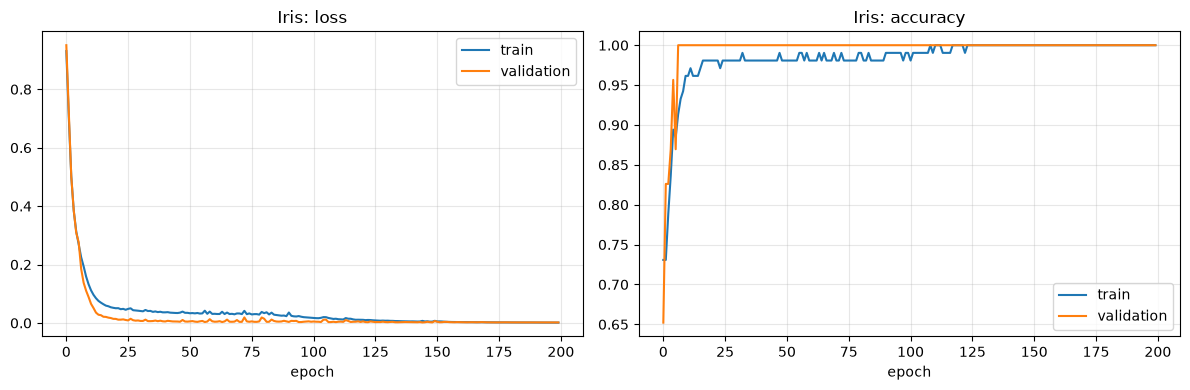

In [9]:
def evaluate_multi(model, X, y, criterion):
    model.eval()
    with torch.no_grad():
        logits = model(X)
        loss = criterion(logits, y).item()
        acc = (logits.argmax(dim=1) == y).float().mean().item()
    return loss, acc

def train_iris(epochs=200, lr=1e-2, batch_size=16, seed=SEED):
    torch.manual_seed(seed)
    model = MLP(4, hidden=(16, 8), n_out=3)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loader = DataLoader(TensorDataset(Xi_train_t, yi_train_t), batch_size=batch_size, shuffle=True)

    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    for epoch in range(epochs):
        model.train()
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
        tl, ta = evaluate_multi(model, Xi_train_t, yi_train_t, criterion)
        vl, va = evaluate_multi(model, Xi_val_t,   yi_val_t,   criterion)
        hist["train_loss"].append(tl); hist["train_acc"].append(ta)
        hist["val_loss"].append(vl);   hist["val_acc"].append(va)
    return model, hist

iris_model, iris_hist = train_iris()
print(f"final train acc {iris_hist['train_acc'][-1]:.3f} | val acc {iris_hist['val_acc'][-1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(iris_hist["train_loss"], label="train"); axes[0].plot(iris_hist["val_loss"], label="validation")
axes[0].set_title("Iris: loss"); axes[0].set_xlabel("epoch"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(iris_hist["train_acc"], label="train"); axes[1].plot(iris_hist["val_acc"], label="validation")
axes[1].set_title("Iris: accuracy"); axes[1].set_xlabel("epoch"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

pehle 5 test samples ki probabilities (har row ka sum = 1):
[[0.008 0.992 0.   ]
 [0.    0.525 0.475]
 [0.    0.001 0.999]
 [0.    1.    0.   ]
 [1.    0.    0.   ]]
predicted: [1 1 2 1 0]  actual: [1 2 1 1 0]

Test accuracy: 0.913  (test set size: 23)

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00         7
  versicolor       0.88      0.88      0.88         8
   virginica       0.88      0.88      0.88         8

    accuracy                           0.91        23
   macro avg       0.92      0.92      0.92        23
weighted avg       0.91      0.91      0.91        23



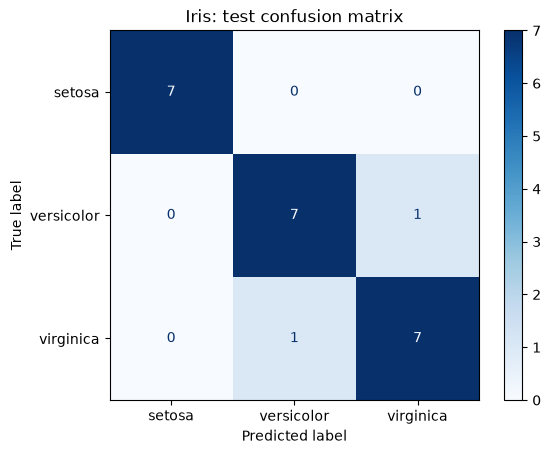

In [10]:
iris_model.eval()
with torch.no_grad():
    logits = iris_model(Xi_test_t)
    probs = torch.softmax(logits, dim=1)       # softmax sirf probabilities dikhane ke liye
    preds = logits.argmax(dim=1).numpy()

print("pehle 5 test samples ki probabilities (har row ka sum = 1):")
print(np.round(probs[:5].numpy(), 3))
print("predicted:", preds[:5], " actual:", yi_test[:5])
print()
print(f"Test accuracy: {(preds == yi_test).mean():.3f}  (test set size: {len(yi_test)})")
print()
print(classification_report(yi_test, preds, target_names=iris.target_names))

cm = confusion_matrix(yi_test, preds)
ConfusionMatrixDisplay(cm, display_labels=iris.target_names).plot(cmap="Blues")
plt.title("Iris: test confusion matrix")
plt.savefig(f"{IMG_DIR}/iris_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

Iris ka test set sirf 23 samples ka hai, isliye ek galti se accuracy lagbhag 4% badal jati hai.

## Wrap-up checklist

- [ ] Sab notebooks **Run All** karke save kiye (taake GitHub par plots dikhen)
- [ ] README me har `TODO` bhar diya
- [ ] Plots (loss curves, confusion matrices) images me save karke README me daale
- [ ] GitHub par push kiya aur repo link trainer ko mail me bheja

## Notes (apne words me likho)

- Overfitting aur underfitting curves par kaise dikhte hain:
- Dropout, weight decay, early stopping har ek kaise madad karta hai:
- Regularization ne is dataset par kya badla (honestly):
- Multi-class me softmax aur `CrossEntropyLoss` kaise kaam karte hain:
- Is hafte kya seekha: